# P7 · Does emotion improve matched-pair prediction?

E0 uses seven GoEmotions scores alone. P7 adds those scores to P6. Each input is the difference between the scores for replies A and B. We reuse the randomized pair orientation and three discussion-grouped folds from P6. Scaling and logistic regression are fit separately inside each training fold.

The checkpoint is [SamLowe/roberta-base-go_emotions](https://huggingface.co/SamLowe/roberta-base-go_emotions/tree/9045a3949b4d643baee6296673cea5bbfdc66c04). Each opening uses the maximum score across its chunks for each label. Longer openings offer more opportunities for a high chunk score. The 0.50 threshold is used for descriptive detection counts. E0 and P7 use continuous scores. Manual label validation is pending.

In [6]:
import json
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd

root = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "project/notebooks/linguistic-features/models").is_dir()
)
result_root = root / "project/data/processed/linguistic-features/paired-models/p7_p6_plus_goemotions"
run_id = None  # Set a run folder name to reopen a specific experiment.
runs = sorted(path.parent for path in result_root.glob("*/results.json"))
if run_id is None and not runs:
    raise FileNotFoundError("Run train_p7_p6_plus_goemotions.py to generate results.")
run = result_root / run_id if run_id else runs[-1]
manifest = json.loads((run / "results.json").read_text())
print(f'{manifest["pairs"]:,} training pairs · {manifest["discussions"]:,} OP discussions · {manifest["folds"]} grouped folds')
metrics = pd.read_csv(run / "predictive_comparison.csv")

3,451 training pairs · 2,507 OP discussions · 3 grouped folds


## Out-of-fold model performance

The intervals compare each model against P6 using the same resampled OP discussions. Positive changes favor the new model for AUC, average precision, and accuracy. Negative changes favor it for log loss.

In [7]:
display(metrics.pivot(index="metric", columns="model", values="value")[["E0", "P6", "P7"]].round(4))
p7 = metrics.loc[metrics["model"].eq("P7")].set_index("metric")
display(p7[["delta_vs_p6", "delta_ci_low", "delta_ci_high"]].round(4))

model,E0,P6,P7
metric,,,
Average precision,0.5200,0.7341,0.7300
Log loss,0.6920,0.5966,0.5996
Pairwise accuracy,0.5317,0.6801,0.6772
ROC-AUC,0.5402,0.7468,0.7438


,delta_vs_p6,delta_ci_low,delta_ci_high
metric,,,
ROC-AUC,-0.0031,-0.0051,-0.0011
Average precision,-0.0041,-0.0069,-0.0016
Pairwise accuracy,-0.0029,-0.0078,0.0017
Log loss,0.0031,0.0015,0.0047


## Does the continuous neutral score add value by itself?

GoEmotions gives neutral its own score. This comparison uses the raw A-minus-B neutral score difference across the same three discussion-grouped folds. E0 neutral uses that difference alone. P7 neutral adds it to P6. The 0.50 detection cutoff is only used in the descriptive section below.

In [8]:
neutral_root = result_root.with_name("p7_p6_plus_continuous_neutral")
neutral_runs = sorted(path.parent for path in neutral_root.glob("*/results.json"))
if not neutral_runs:
    print("Run train_p7_p6_plus_continuous_neutral.py to generate this comparison.")
else:
    neutral_run = neutral_runs[-1]
    neutral_metrics = pd.read_csv(neutral_run / "predictive_comparison.csv")
    display(neutral_metrics.pivot(index="metric", columns="model", values="value")
            [["E0 neutral", "P6", "P7 neutral"]].round(4))
    neutral_delta = neutral_metrics.loc[neutral_metrics["model"].eq("P7 neutral")].set_index("metric")
    display(neutral_delta[["delta_vs_p6", "delta_ci_low", "delta_ci_high"]].round(4))

    neutral_manifest = json.loads((neutral_run / "results.json").read_text())
    neutral_association = pd.DataFrame.from_dict(neutral_manifest["neutral_score_association"], orient="index")
    neutral_association["unequal pairs"] = neutral_association["winner_higher"] + neutral_association["winner_lower"]
    neutral_association[["CI low", "CI high"]] = pd.DataFrame(
        neutral_association["ci_95"].tolist(), index=neutral_association.index,
    )
    display(neutral_association.rename(columns={"winner_higher_rate": "winner scored higher"})
            [["unequal pairs", "winner scored higher", "CI low", "CI high"]].round(4))

model,E0 neutral,P6,P7 neutral
metric,,,
Average precision,0.5213,0.7341,0.7340
Log loss,0.6912,0.5966,0.5967
Pairwise accuracy,0.5335,0.6801,0.6815
ROC-AUC,0.5395,0.7468,0.7466


,delta_vs_p6,delta_ci_low,delta_ci_high
metric,,,
ROC-AUC,-0.0002,-0.0007,0.0003
Average precision,-0.0001,-0.0007,0.0006
Pairwise accuracy,0.0014,-0.0020,0.0050
Log loss,0.0002,-0.0002,0.0005


,unequal pairs,winner scored higher,CI low,CI high
All training pairs,3450,0.5359,0.5186,0.5543
Within 50 words,1143,0.5179,0.4907,0.5491


## Which emotions were detected?

Both segments use the full matched cohort as the denominator. Each pair contributes one winner and one comparison appearance. Replies can contribute to several emotion bars, and a reply reused across pairs contributes once per appearance.

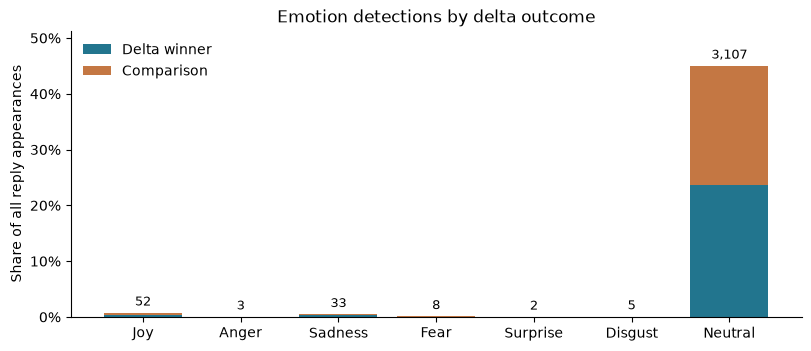

,winner_count,comparison_count
emotion,,
joy,27,25
anger,1,2
sadness,18,15
fear,4,4
surprise,1,1
disgust,2,3
neutral,1637,1470


In [9]:
prevalence = pd.read_csv(run / "emotion_prevalence.csv").set_index("emotion")
denominator = 2 * prevalence["reply_appearances_per_role"]
winner = prevalence["winner_count"] / denominator
comparison = prevalence["comparison_count"] / denominator

fig, ax = plt.subplots(figsize=(8, 3.4), layout="constrained")
positions = np.arange(len(prevalence))
ax.bar(positions, winner, label="Delta winner", color="#22758e")
ax.bar(positions, comparison, bottom=winner, label="Comparison", color="#c47743")
for x, height, count in zip(positions, winner + comparison,
                            prevalence["winner_count"] + prevalence["comparison_count"]):
    ax.annotate(f"{count:,}", (x, height), xytext=(0, 3), textcoords="offset points",
                ha="center", va="bottom", fontsize=9)
ax.set_xticks(positions, [label.title() for label in prevalence.index])
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(ylabel="Share of all reply appearances", title="Emotion detections by delta outcome")
ax.margins(y=0.14)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()
display(prevalence[["winner_count", "comparison_count"]])

## Which emotions distinguished winners?

For detections, win share is the fraction of discordant pairs where the reply with the detection won. For continuous scores, it is the fraction of unequal-score pairs where the higher-scoring reply won. Show the informative sample size with each result, especially for rare detections.

In [10]:
associations = pd.read_csv(run / "paired_emotion_associations.csv")
columns = ["cohort", "emotion", "informative_pairs", "winner_higher_rate", "ci_low", "ci_high"]
detection = associations.loc[associations["measure"].eq("detected"), columns]
continuous = associations.loc[associations["measure"].eq("continuous_score"), columns]
display(detection.set_index(["cohort", "emotion"]).round(3))
display(continuous.set_index(["cohort", "emotion"]).round(3))

informative_pairs  winner_higher_rate  ci_low  \
cohort             emotion                                                   
All training pairs joy                      50               0.520   0.353   
                   anger                     3               0.333   0.000   
                   sadness                  29               0.552   0.357   
                   fear                      6               0.500   0.167   
                   surprise                  2               0.500   0.000   
                   disgust                   5               0.400   0.000   
                   neutral                1493               0.556   0.528   
Within 50 words    joy                      19               0.632   0.421   
                   anger                     0                 NaN     NaN   
                   sadness                   9               0.444   0.111   
                   fear                      3               0.667   0.000   
                   surprise                  0                 NaN     NaN   
                   disgust                   0                 NaN     NaN   
                   neutral                 478               0.536   0.491   

                             ci_high  
cohort             emotion            
All training pairs joy         0.685  
                   anger       1.000  
                   sadness     0.750  
                   fear        0.833  
                   surprise    1.000  
                   disgust     0.800  
                   neutral     0.582  
Within 50 words    joy         0.824  
                   anger         NaN  
                   sadness     0.778  
                   fear        1.000  
                   surprise      NaN  
                   disgust       NaN  
                   neutral     0.579

informative_pairs  winner_higher_rate  ci_low  \
cohort             emotion                                                   
All training pairs joy                    3450               0.515   0.497   
                   anger                  3450               0.477   0.459   
                   sadness                3450               0.539   0.521   
                   fear                   3450               0.520   0.502   
                   surprise               3450               0.518   0.501   
                   disgust                3450               0.491   0.473   
                   neutral                3450               0.536   0.519   
Within 50 words    joy                    1143               0.507   0.477   
                   anger                  1143               0.458   0.429   
                   sadness                1143               0.520   0.490   
                   fear                   1143               0.493   0.463   
                   surprise               1143               0.508   0.480   
                   disgust                1143               0.454   0.424   
                   neutral                1143               0.518   0.491   

                             ci_high  
cohort             emotion            
All training pairs joy         0.531  
                   anger       0.493  
                   sadness     0.557  
                   fear        0.537  
                   surprise    0.537  
                   disgust     0.509  
                   neutral     0.554  
Within 50 words    joy         0.535  
                   anger       0.489  
                   sadness     0.547  
                   fear        0.521  
                   surprise    0.538  
                   disgust     0.483  
                   neutral     0.549

The chart shows estimates for at least 30 informative pairs. The counts include smaller groups, whose estimates are listed in the table above.

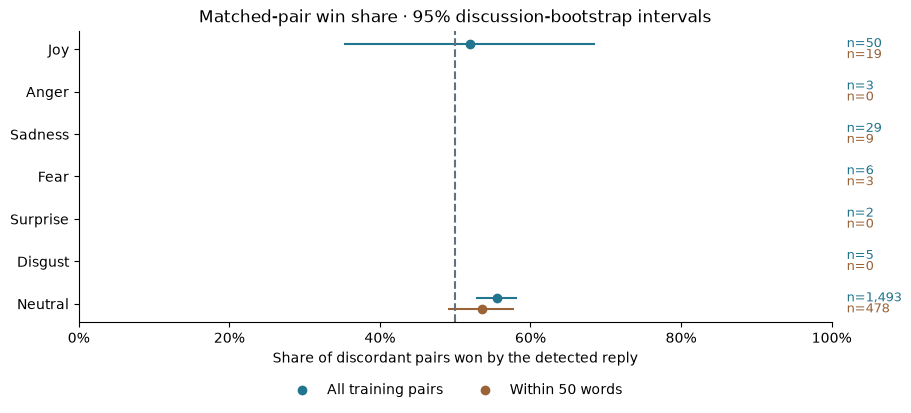

In [11]:
labels = prevalence.index.tolist()
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
for cohort, color, offset in [("All training pairs", "#22758e", -0.13),
                              ("Within 50 words", "#9b6338", 0.13)]:
    rows = detection.loc[detection["cohort"].eq(cohort)].set_index("emotion").loc[labels]
    y = np.arange(len(labels)) + offset
    supported = rows["informative_pairs"].ge(30)
    ax.hlines(y[supported], rows.loc[supported, "ci_low"], rows.loc[supported, "ci_high"], color=color)
    ax.scatter(rows.loc[supported, "winner_higher_rate"], y[supported], color=color, label=cohort)
    for level, count in zip(y, rows["informative_pairs"]):
        ax.annotate(f"n={count:,}", (1.02, level), xycoords=ax.get_yaxis_transform(),
                    va="center", color=color, fontsize=9)
ax.axvline(0.5, color="#647080", linestyle="--")
ax.set_yticks(np.arange(len(labels)), [label.title() for label in labels])
ax.set(xlim=(0, 1), xlabel="Share of discordant pairs won by the detected reply",
       title="Matched-pair win share · 95% discussion-bootstrap intervals")
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, -0.3), ncols=2)
ax.spines[["top", "right"]].set_visible(False)
plt.show()